WEEK 1-LAB 0:Setting up the DSP laboratory

Name:MONICA SAMWEL MWAKAPALA

REG No:240242405330

Task1.1:Elementary Discrete-time sequences

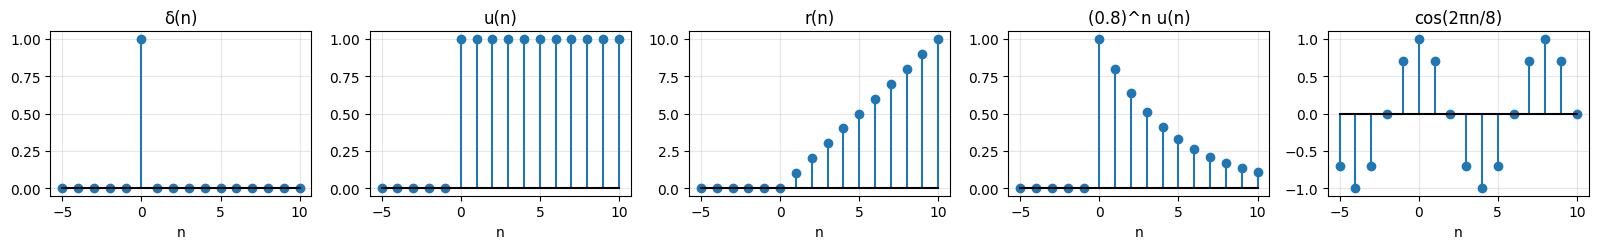

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step  = (n >= 0).astype(float)      # unit step
ramp  = n * step                    # unit ramp
expo  = 0.8**n * step               # real exponential
cos_seq = np.cos(2 * np.pi * n / 8) # sinusoidal sequence

fig, axes = plt.subplots(1, 5, figsize=(16, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo, cos_seq],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)", "cos(2πn/8)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Task:Change the parameter

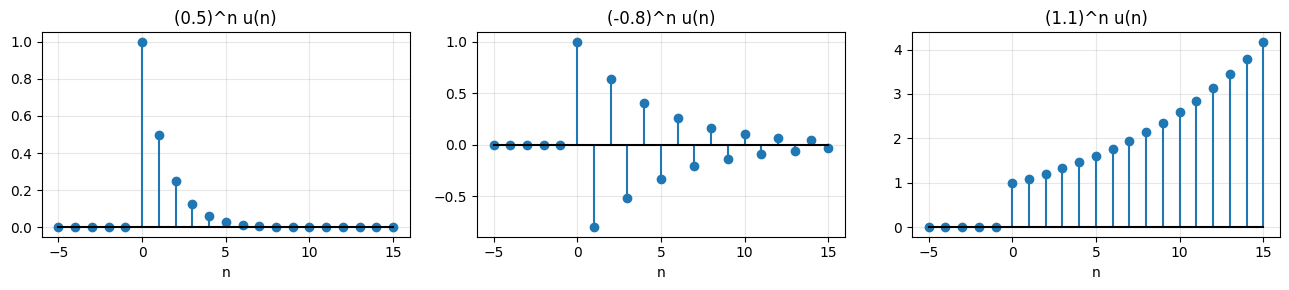

In [ ]:
n = np.arange(-5, 16)
step = (n >= 0).astype(float)

a_values = [0.5, -0.8, 1.1]
fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):
    x = (a**n) * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

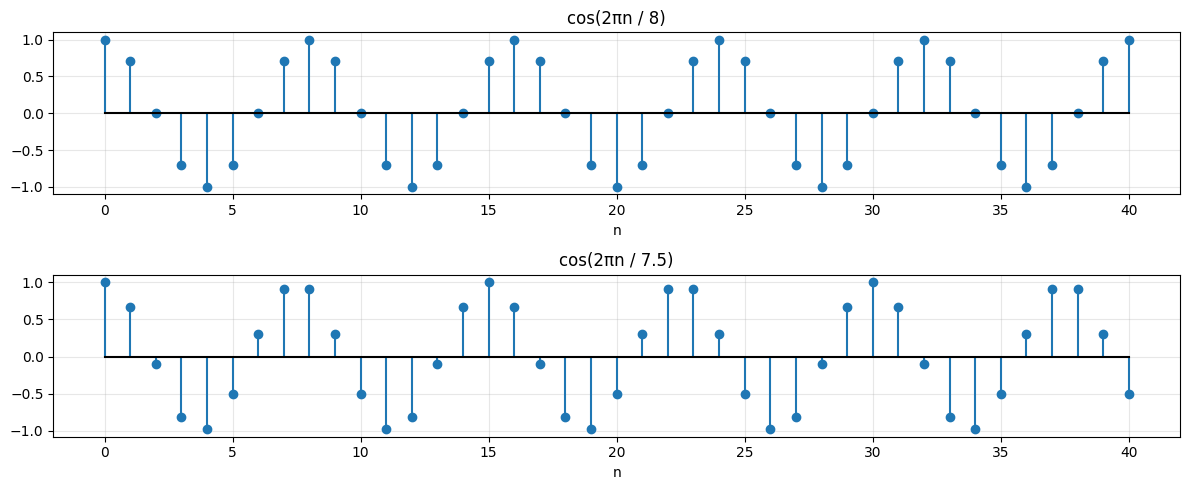

In [ ]:
n2 = np.arange(0, 41)
cos_8 = np.cos(2 * np.pi * n2 / 8)
cos_75 = np.cos(2 * np.pi * n2 / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(12, 5))

axes[0].stem(n2, cos_8, basefmt="k-")
axes[0].set_title("cos(2πn / 8)")
axes[0].set_xlabel("n")
axes[0].grid(True, alpha=0.3)

axes[1].stem(n2, cos_75, basefmt="k-")
axes[1].set_title("cos(2πn / 7.5)")
axes[1].set_xlabel("n")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Task1.3:Working with audio

fs = 16000 Hz, duration = 2.00 s, samples = 32000


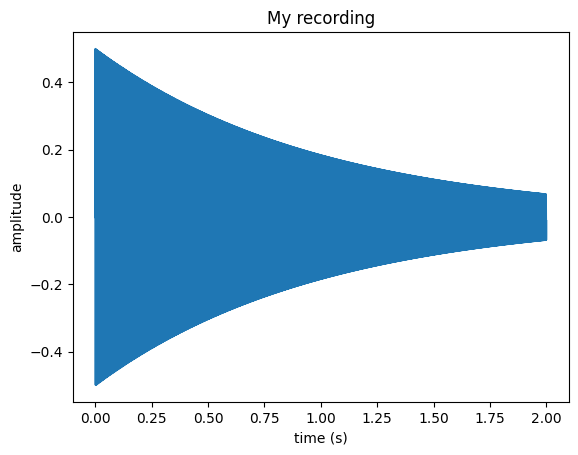

In [ ]:
import os
from scipy.io import wavfile
from IPython.display import Audio

fname = "my_voice.wav"             # hakikisha jina linafanana na faili ulilo-upload
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                 # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))      # normalise to [-1, 1]
else:                              # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

# Kicheza sauti (Audio player) ndani ya notebook
Audio(x, rate=fs)

Task1.4:The same in octave

*Syntax Comparison (Python/NumPy vs. GNU Octave):**
* **Range creation:** Python uses `np.arange(-5, 11)` (excludes the stop value `11`), while Octave uses `-5:10` (includes both endpoints).
* **Type casting:** Python uses `.astype(float)`, while Octave uses `double(...)`.
* **Element-wise power:** Python uses `**` (e.g., `0.8**n`), while Octave uses `.^` (e.g., `0.8.^n`).
* **Indexing:** Python starts indexing at `0`, whereas Octave starts indexing at `1`.

Analysis Question



1. **What is the sampling rate of your phone’s recording? How many numbers are needed to store one minute of it in mono?**
   * **Sampling rate ($f_s$):** $16,000\text{ Hz}$
   * **Numbers needed for 1 minute ($60\text{ seconds}$) in mono:**  
     $$\text{Total samples} = 16,000\text{ samples/s} \times 60\text{ s} = \mathbf{960,000\text{ numbers}}$$

2. **Why is a stem plot more appropriate than a continuous line for $x(n)$?**
   * Because $x(n)$ is a **discrete-time signal** defined only at integer sample indices $n$. A stem plot accurately shows that values exist only at discrete instants and are undefined between integers, whereas a continuous line falsely implies the signal exists at non-integer times.

3. **For $a = 1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?**
   * It would violate **BIBO Stability (Bounded-Input, Bounded-Output stability)**. For an LTI system to be BIBO stable, its impulse response must be absolutely summable ($\sum_{n=-\infty}^{\infty} |h(n)| < \infty$). Since $(1.1)^n u(n)$ grows without bound as $n \to \infty$, the sum diverges to infinity, making the system unstable.